# Experimental regional model: training and evaluation
LightGBM was selected in 2022, a probability transform was fitted
in 2023 and then the evaluations were opened. The label is a detected start,
not a verified physical ignition. This version is not published in the API.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display,Markdown,Image

repo=next(p for p in [Path.cwd(),*Path.cwd().parents]
          if (p/'reports/prediction/model/training_evaluation_report.json').exists())
folder=repo/'reports/prediction/model'
load=lambda name:json.loads((folder/name).read_text(encoding='utf-8'))
report=load('training_evaluation_report.json')
protocol=load('training_protocol_frozen.json')
scores=pd.read_csv(folder/'evaluation_metrics.csv')
selected=report['selected']['all_regions']
figures=repo.parent.parent/'outputs/39_modelo_riesgo_regional/figures'
figures.mkdir(parents=True,exist_ok=True)

def show(fig,name):
    fig.tight_layout()
    path=figures/name
    fig.savefig(path,dpi=150)
    plt.close(fig)
    display(Image(filename=str(path)))

print('Modelo seleccionado:',selected)
print('Versión:',report['method_version'])
print('Software:',report['software'])
print('Modelo cambiado tras la prueba:',report['model_selection_from_test'])
print('Ignición física validada:',report['physical_ignition_probability_verified'])

Modelo seleccionado: lgbm_without_harmonization
Versión: regional-onset-proxy-v0.1
Software: {'python': '3.13.15', 'lightgbm': '4.7.0', 'sklearn': '1.9.1', 'pandas': '3.0.5', 'numpy': '2.5.3'}
Modelo cambiado tras la prueba: False
Ignición física validada: False


## 1. Split and selection
Fitting 2018–2021, selection 2022 and calibration 2023. The 2024–2025 test is
retrospective because the project already examined those years. The 2026 confirmation
was opened after freezing the model. Eight predefined candidates, without
rebalancing classes; complex ones need a Brier improvement of at least 1 %.

In [2]:
selection=pd.read_csv(folder/'selection_metrics.csv')
display(selection.loc[selection.scope.eq('all_regions'),
                      ['model','macro_lead_brier','average_precision','fit_seconds','best_iteration']])
display(Markdown('**Resultado:** el candidato sin variables de contexto armonizado ganó '
                 'en selección. No añadieron mejora incremental en este experimento; '
                 'esto no reemplaza ni invalida el producto histórico de armonización.'))

,model,macro_lead_brier,average_precision,fit_seconds,best_iteration
0,constant,0.129445,0.846300,0.183664,NaN
1,climatology,0.072970,0.985108,0.083524,NaN
2,logistic,0.073906,0.985268,1.730294,NaN
3,lgbm_small,0.070566,0.987397,1.020206,225.0
4,lgbm_medium,0.070296,0.987473,3.354445,187.0
5,lgbm_deeper,0.070926,0.986894,4.886965,184.0
6,lgbm_without_weather,0.071031,0.987073,0.935868,164.0
7,lgbm_without_harmonization,0.070173,0.988080,0.944101,213.0


**Resultado:** el candidato sin variables de contexto armonizado ganó en selección. No añadieron mejora incremental en este experimento; esto no reemplaza ni invalida el producto histórico de armonización.

## 2. Comparison outside the fit
Brier measures the error of probabilities and lower is better. Average precision is
read against the high prevalence, not as a percentage of correct answers.

,period,model,positive_fraction,brier,average_precision,ece_10_equal_width
1,2024,climatology,0.823141,0.082997,0.977852,0.040766
7,2024,lgbm_without_harmonization,0.823141,0.083020,0.981649,0.020193
9,2025,climatology,0.835897,0.074349,0.983314,0.038112
15,2025,lgbm_without_harmonization,0.835897,0.067818,0.988291,0.034584
17,confirmation_2026,climatology,0.792624,0.092859,0.966221,0.045162
23,confirmation_2026,lgbm_without_harmonization,0.792624,0.089194,0.977006,0.034635


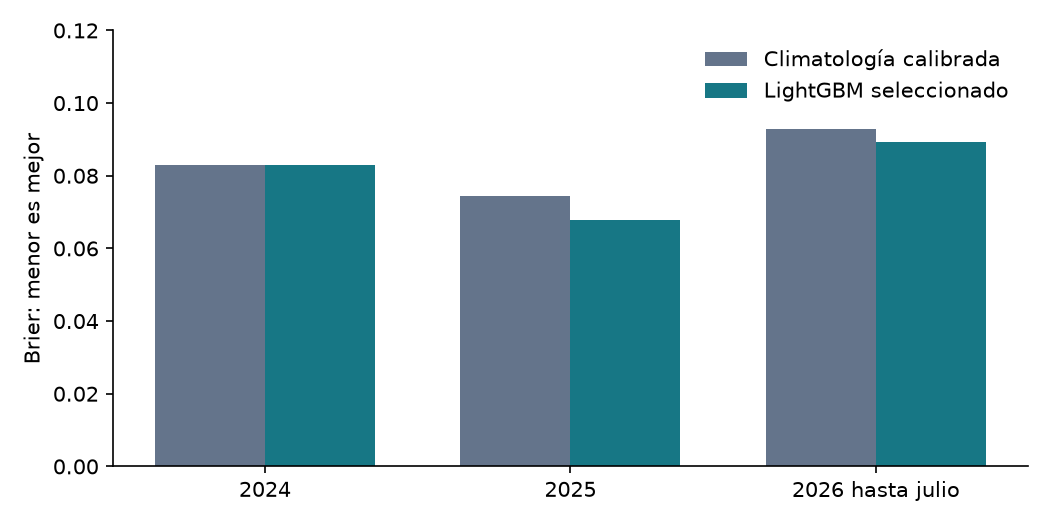

Comparación por bloques: {'target_week_blocks': 9, 'block_weeks': 13, 'replicates': 1000, 'brier_gain_selected_vs_calibrated_climatology': 0.0030357683914495667, 'lower_95': -0.0008154582330094199, 'upper_95': 0.0068246617035049445, 'uncertainty_scope': 'fixed fitted models; resampled target-week blocks, not row-independent errors or ignition uncertainty'}


**Lectura:** prácticamente empate en 2024, mejora en 2025 y 2026. El intervalo de mejora conjunta incluye cero; no se demuestra superioridad consistente entre estaciones o años.

In [3]:
comparison=scores.loc[scores.scope.eq('all_regions') &
                     scores.model.isin(['climatology',selected])]
display(comparison[['period','model','positive_fraction','brier','average_precision','ece_10_equal_width']])
wide=comparison.pivot(index='period',columns='model',values='brier').reindex(['2024','2025','confirmation_2026'])
fig,ax=plt.subplots(figsize=(7,3.5))
x=np.arange(len(wide))
ax.bar(x-.18,wide.climatology,.36,label='Climatología calibrada',color='#64748b')
ax.bar(x+.18,wide[selected],.36,label='LightGBM seleccionado',color='#177785')
ax.set_xticks(x,['2024','2025','2026 hasta julio'])
ax.set_ylabel('Brier: menor es mejor')
ax.set_ylim(0,.12)
ax.legend(frameon=False)
ax.spines[['top','right']].set_visible(False)
show(fig,'comparison_brier.png')
print('Comparación por bloques:',report['block_comparisons']['all_regions'])
display(Markdown('**Lectura:** prácticamente empate en 2024, mejora en 2025 y 2026. '
                 'El intervalo de mejora conjunta incluye cero; no se demuestra '
                 'superioridad consistente entre estaciones o años.'))

## 3. Calibration: a transform does not guarantee improvement
The per-lead-time transform was fixed with 2023. The later evaluation
does not improve the joint Brier or ECE. We do not switch to the uncalibrated variant
after looking at the test. The following points are not confidence intervals.

,antes,después
brier,0.07587,0.075926
log_loss,0.241716,0.246476
ece_10_equal_width,0.014832,0.021315
mean_probability,0.840135,0.817228
positive_fraction,0.829094,0.829094


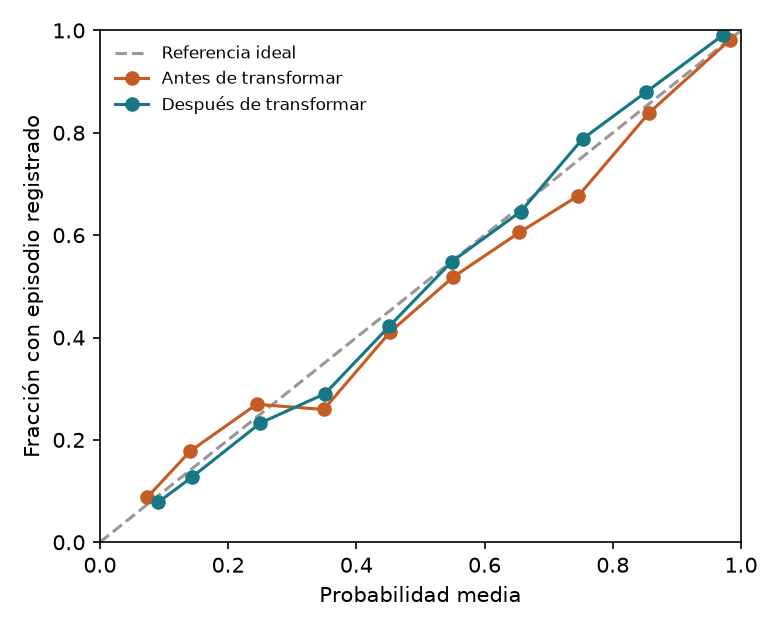

,bin,rows,mean_probability,observed_fraction
10,0,167,0.090542,0.077844
11,1,1037,0.143599,0.127290
12,2,760,0.250243,0.232895
13,3,934,0.350941,0.290150
14,4,1009,0.451523,0.422200
15,5,1116,0.548986,0.548387
16,6,1840,0.656490,0.646196
17,7,1992,0.752930,0.788153
18,8,3024,0.851667,0.879299
19,9,17371,0.971185,0.990271


Los grupos tienen tamaños distintos: la cercanía visual de algunos puntos a la diagonal no sustituye las métricas ponderadas.

In [4]:
cal=load('calibration_diagnostic.json')
display(pd.DataFrame({'antes':cal['retrospective_before'],'después':cal['retrospective_after']}).loc[
    ['brier','log_loss','ece_10_equal_width','mean_probability','positive_fraction']])
bins=pd.read_csv(folder/'calibration_bins.csv')
fig,ax=plt.subplots(figsize=(5.2,4.2))
ax.plot([0,1],[0,1],linestyle='--',color='#999999',label='Referencia ideal')
for variant,label,color in [('selected_raw','Antes de transformar','#c45c24'),
                            ('selected_calibrated','Después de transformar','#177785')]:
    g=bins.loc[bins.variant.eq(variant)]
    ax.plot(g.mean_probability,g.observed_fraction,'o-',label=label,color=color)
ax.set(xlim=(0,1),ylim=(0,1),xlabel='Probabilidad media',ylabel='Fracción con episodio registrado')
ax.legend(frameon=False,fontsize=8)
show(fig,'calibration.png')
display(bins.loc[bins.variant.eq('selected_calibrated'),
                 ['bin','rows','mean_probability','observed_fraction']])
display(Markdown('Los grupos tienen tamaños distintos: la cercanía visual de '
                 'algunos puntos a la diagonal no sustituye las métricas ponderadas.'))

## 4. Comparable lead times and difficult regions
Each lead time has different calendars because of label maturity.
To compare horizons, the same target weeks are used. A descending curve
is not read as automatic evidence of better prediction at 12 weeks.

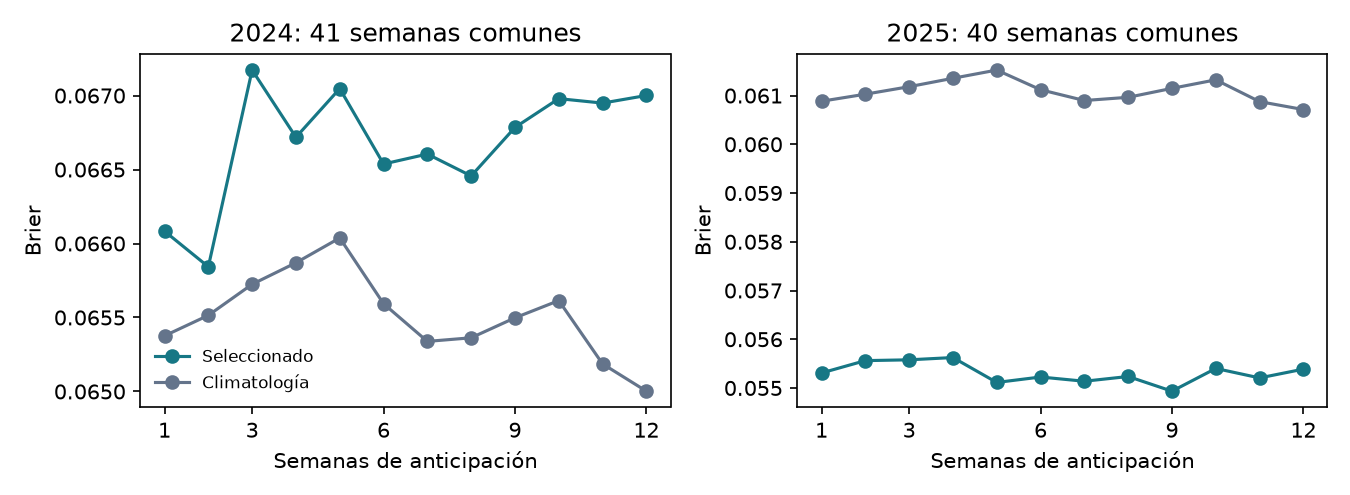

,period,region_id,brier,positive_fraction,mean_probability
17,2024,18,0.272890,0.586538,0.499697
72,confirmation_2026,23,0.268604,0.656028,0.491352
47,2025,23,0.251158,0.439560,0.526772
22,2024,23,0.232358,0.451923,0.514801
42,2025,18,0.193529,0.602564,0.536468
52,confirmation_2026,03,0.179174,0.475177,0.491269
2,2024,03,0.176515,0.524038,0.633747
66,confirmation_2026,17,0.172805,0.773050,0.793969
54,confirmation_2026,05,0.165253,0.751773,0.676175
67,confirmation_2026,18,0.157549,0.329787,0.381245


**Lectura:** Moquegua y Tacna aparecen entre los errores mayores. Sus casos se conservan y no se escoge otro modelo por región usando el test.

In [5]:
matched=pd.read_csv(folder/'matched_target_week_lead_metrics.csv')
fig,axes=plt.subplots(1,2,figsize=(9,3.3))
for period,ax in zip(['2024','2025'],axes):
    g=matched.loc[matched.period.eq(int(period))]
    ax.plot(g.lead_weeks,g.brier,'o-',label='Seleccionado',color='#177785')
    ax.plot(g.lead_weeks,g.climatology_brier,'o-',label='Climatología',color='#64748b')
    ax.set(title=f'{period}: {int(g.common_target_weeks.iloc[0])} semanas comunes',
           xlabel='Semanas de anticipación',ylabel='Brier')
    ax.set_xticks([1,3,6,9,12])
axes[0].legend(frameon=False,fontsize=8)
show(fig,'matched_leads.png')
regions=pd.read_csv(folder/'evaluation_by_region.csv',dtype={'region_id':str})
display(regions.loc[regions.scope.eq('all_regions')].sort_values('brier',ascending=False)[
    ['period','region_id','brier','positive_fraction','mean_probability']].head(10))
display(Markdown('**Lectura:** Moquegua y Tacna aparecen entre los errores mayores. '
                 'Sus casos se conservan y no se escoge otro modelo por región usando el test.'))

## 5. Spatial generalization, importance and robustness
The targets of five departments are excluded from the fitting, selection and
calibration of the shadow model. Their local history is still available as a feature.
Permuting features measures marginal predictive dependence, not causality.

,period,model,brier,average_precision,ece_10_equal_width
25,2024,climatology,0.090922,0.977639,0.134023
31,2024,lgbm_without_harmonization,0.071178,0.972936,0.010433
33,2025,climatology,0.069466,0.993480,0.146769
39,2025,lgbm_without_harmonization,0.047909,0.992763,0.018648
41,confirmation_2026,climatology,0.109938,0.970198,0.180133
47,confirmation_2026,lgbm_without_harmonization,0.075794,0.974051,0.017415


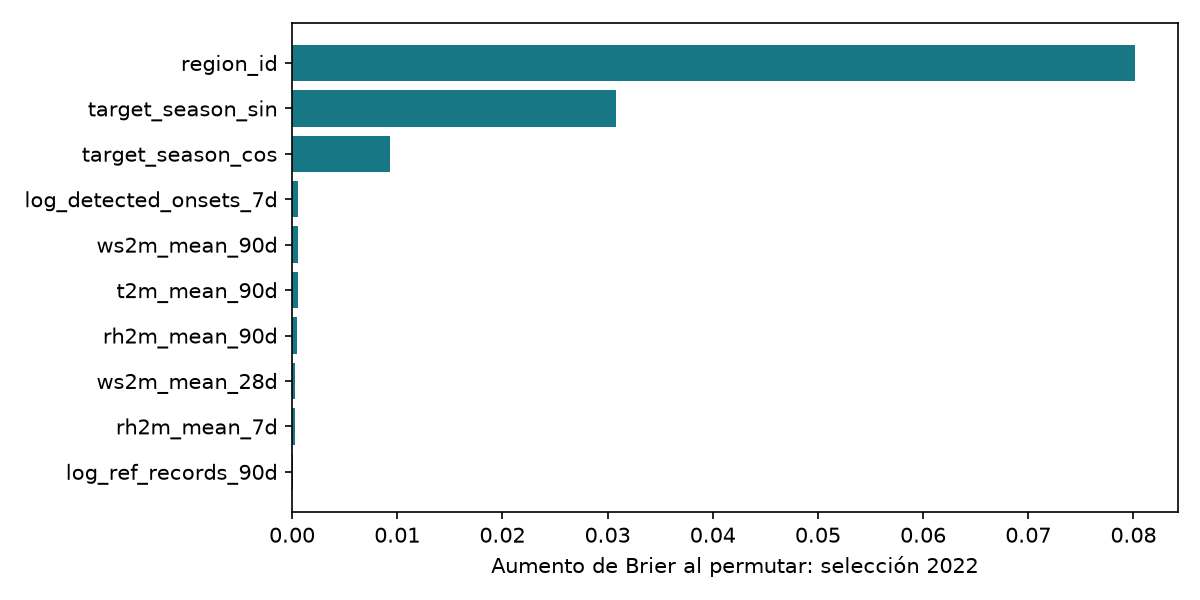

,scenario,brier,mean_absolute_probability_change,is_real_NRT_validation
0,weather_missing,0.080536,0.031141,False
1,record_counts_minus30percent,0.075990,0.001135,False
2,record_counts_plus30percent,0.075861,0.001456,False


Brier sin perturbación: 0.07592581647466443
Matriz a umbral 0.5, solo diagnóstico: {'threshold': 0.5, 'threshold_is_operational_policy': False, 'labels': ['no new episode recorded', 'new episode recorded'], 'matrix_true_rows_predicted_columns': [[2888, 2111], [1019, 23232]]}


**Lectura:** región y estación dominan la señal. Las perturbaciones no prueban transferencia SP/NRT ni definen un umbral operativo.

In [6]:
shadow=scores.loc[scores.scope.eq('spatial_shadow') & scores.model.isin(['climatology',selected])]
display(shadow[['period','model','brier','average_precision','ece_10_equal_width']])
importance=pd.read_csv(folder/'permutation_importance_selection.csv').head(10).iloc[::-1]
fig,ax=plt.subplots(figsize=(8,4))
ax.barh(importance.feature,importance.brier_increase_mean,color='#177785')
ax.set_xlabel('Aumento de Brier al permutar: selección 2022')
show(fig,'importance.png')
robust=load('robustness_diagnostic.json')
display(pd.DataFrame(robust['scenarios']))
print('Brier sin perturbación:',robust['baseline']['brier'])
print('Matriz a umbral 0.5, solo diagnóstico:',load('diagnostic_confusion.json'))
display(Markdown('**Lectura:** región y estación dominan la señal. Las perturbaciones '
                 'no prueban transferencia SP/NRT ni definen un umbral operativo.'))

## 6. Usable artifact and next review
The model was saved and reloaded without changing predictions at a 1e-12 tolerance.
Still to do: build the current features with the same logic, generate the
300 region/lead-time queries, check NRT and publish the new route with its
metadata. The public API has not been changed. The ignition review and a
prospective pilot are still pending; no human losses are assigned.

In [7]:
freeze=load('model_freeze_before_test.json')
assert freeze['test_performance_opened'] is False
assert report['retrospective_test_evaluated'] is True
assert freeze['choices']==report['selected']
assert report['public_api_modified'] is False
print('SHA-256 modelo:',report['model_sha256'])
print('SHA-256 congelamiento previo a prueba:',report['freeze_before_test_sha256'])
print('Paridad de serialización:',report['serialization_prediction_parity_atol'])
display(Markdown('**Avance: 70 % por entregables.** Modelo experimental entrenado, '
                 'transformado y evaluado. Pendientes inferencia NRT, integración y revisión de publicación.'))

SHA-256 modelo: 68e3ab38955168b2b0c69a7f2f175ef26205e4a23f4b46a3a05ae8041e12ecd4
SHA-256 congelamiento previo a prueba: debff124d07b370d91a3965a3396b5cd981a3dce95de93c1d3978fb17ad72ba5
Paridad de serialización: 1e-12


**Avance: 70 % por entregables.** Modelo experimental entrenado, transformado y evaluado. Pendientes inferencia NRT, integración y revisión de publicación.